<a href="https://colab.research.google.com/github/kiethema123-csm/Team4/blob/main/Incredible_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================
# CELL 1: IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SymPy is useful for displaying mathematical expressions/eigenvalues
import sympy as sp

# Make numerical output easier to read
np.set_printoptions(precision=4, suppress=True)

# Plotting style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# ============================================
# CELL 2: USER CONFIGURATION / INPUT DATA
# ============================================

# Subject names
subjects = [
    "Mathematics",
    "Physics",
    "Chemistry",
    "Programming",
    "English"
]

# ------------------------------------------------
# BENCHMARK DATASET
# 30 students × 5 subjects
# Marks are out of 100.
# ------------------------------------------------

marks = np.array([
    [88, 84, 86, 91, 82],
    [76, 72, 75, 79, 74],
    [92, 89, 91, 95, 88],
    [65, 68, 63, 70, 66],
    [81, 79, 80, 84, 77],
    [54, 58, 56, 61, 59],
    [73, 75, 71, 78, 72],
    [95, 93, 94, 97, 91],
    [68, 64, 67, 72, 65],
    [84, 87, 82, 89, 85],

    [59, 62, 60, 65, 63],
    [78, 80, 76, 83, 79],
    [90, 86, 89, 94, 87],
    [70, 73, 69, 76, 71],
    [87, 90, 85, 92, 89],
    [62, 60, 64, 68, 61],
    [75, 71, 74, 80, 73],
    [93, 95, 90, 96, 92],
    [67, 70, 66, 73, 68],
    [82, 78, 81, 86, 80],

    [57, 55, 59, 63, 58],
    [79, 83, 77, 85, 81],
    [89, 91, 87, 93, 90],
    [71, 67, 72, 75, 69],
    [85, 82, 84, 88, 83],
    [64, 66, 62, 69, 65],
    [77, 74, 79, 81, 76],
    [91, 88, 93, 96, 89],
    [69, 72, 68, 74, 70],
    [83, 85, 80, 87, 84]
])

# Student labels
student_names = [f"Student {i}" for i in range(1, len(marks) + 1)]

# Basic validation
assert marks.shape == (30, 5), "Dataset must contain exactly 30 students and 5 subjects."
assert np.all((marks >= 0) & (marks <= 100)), "Marks must be between 0 and 100."

# Create a DataFrame for easier display
student_data = pd.DataFrame(
    marks,
    index=student_names,
    columns=subjects
)

print("Dataset shape:", marks.shape)
print("\nStudent marks:")
display(student_data)

Dataset shape: (30, 5)

Student marks:


,Mathematics,Physics,Chemistry,Programming,English
Student 1,88,84,86,91,82
Student 2,76,72,75,79,74
Student 3,92,89,91,95,88
Student 4,65,68,63,70,66
Student 5,81,79,80,84,77
Student 6,54,58,56,61,59
Student 7,73,75,71,78,72
Student 8,95,93,94,97,91
Student 9,68,64,67,72,65
Student 10,84,87,82,89,85


In [ ]:
# ============================================
# CELL 3: MATHEMATICAL MODEL
# ============================================

print("""
PCA MATHEMATICAL MODEL
======================

Let X be the data matrix.

X has:
    n = 30 students
    p = 5 subjects

Therefore:

        X ∈ R^(30 × 5)

Each row represents one student.
Each column represents one subject.

Step 1:
Center every subject by subtracting its mean.

        X_centered = X - mean(X)

Step 2:
Calculate the covariance matrix.

        C = (1 / (n - 1)) X_centered^T X_centered

Since C is symmetric, its eigenvalues are real and
its eigenvectors can be chosen to be orthogonal.

Step 3:
Solve:

        C v = λ v

where:
    λ = eigenvalue
    v = eigenvector

Step 4:
Sort eigenvalues from largest to smallest.

The eigenvectors corresponding to the two largest
eigenvalues are the first two principal components.

Step 5:
Project each centered student onto these two components:

        Z = X_centered W

where W contains the first two eigenvectors.

Z contains the 2D PCA coordinates of every student.
""")


PCA MATHEMATICAL MODEL

Let X be the data matrix.

X has:
    n = 30 students
    p = 5 subjects

Therefore:

        X ∈ R^(30 × 5)

Each row represents one student.
Each column represents one subject.

Step 1:
Center every subject by subtracting its mean.

        X_centered = X - mean(X)

Step 2:
Calculate the covariance matrix.

        C = (1 / (n - 1)) X_centered^T X_centered

Since C is symmetric, its eigenvalues are real and
its eigenvectors can be chosen to be orthogonal.

Step 3:
Solve:

        C v = λ v

where:
    λ = eigenvalue
    v = eigenvector

Step 4:
Sort eigenvalues from largest to smallest.

The eigenvectors corresponding to the two largest
eigenvalues are the first two principal components.

Step 5:
Project each centered student onto these two components:

        Z = X_centered W

where W contains the first two eigenvectors.

Z contains the 2D PCA coordinates of every student.



In [ ]:
# ============================================
# CELL 4: CENTER THE DATA
# ============================================

# Calculate the mean mark of every subject
subject_means = np.mean(marks, axis=0)

# Center the data
centered_data = marks - subject_means

# Display means
mean_table = pd.DataFrame({
    "Subject": subjects,
    "Mean Mark": subject_means
})

print("Mean mark of each subject:")
display(mean_table)

# Display centered data
centered_df = pd.DataFrame(
    centered_data,
    index=student_names,
    columns=subjects
)

print("\nCentered data matrix:")
display(centered_df.round(3))

# Check that the centered columns have approximately zero mean
print("\nMean of centered columns:")
print(np.mean(centered_data, axis=0))

Mean mark of each subject:


,Subject,Mean Mark
0,Mathematics,76.800000
1,Physics,76.566667
2,Chemistry,76.000000
3,Programming,81.333333
4,English,76.233333



Centered data matrix:


,Mathematics,Physics,Chemistry,Programming,English
Student 1,11.2,7.433,10.0,9.667,5.767
Student 2,-0.8,-4.567,-1.0,-2.333,-2.233
Student 3,15.2,12.433,15.0,13.667,11.767
Student 4,-11.8,-8.567,-13.0,-11.333,-10.233
Student 5,4.2,2.433,4.0,2.667,0.767
Student 6,-22.8,-18.567,-20.0,-20.333,-17.233
Student 7,-3.8,-1.567,-5.0,-3.333,-4.233
Student 8,18.2,16.433,18.0,15.667,14.767
Student 9,-8.8,-12.567,-9.0,-9.333,-11.233
Student 10,7.2,10.433,6.0,7.667,8.767



Mean of centered columns:
[ 0.  0.  0.  0. -0.]


In [ ]:
# ============================================
# CELL 5: COVARIANCE MATRIX
# ============================================

n_students = marks.shape[0]

# Sample covariance matrix:
#
# C = (1 / (n - 1)) X_centered^T X_centered
#
# NumPy's np.cov(..., rowvar=False) uses the same
# sample covariance convention.

covariance_matrix = (
    centered_data.T @ centered_data
) / (n_students - 1)

covariance_df = pd.DataFrame(
    covariance_matrix,
    index=subjects,
    columns=subjects
)

print("Covariance Matrix:")
display(covariance_df.round(4))

# Verify symmetry
is_symmetric = np.allclose(
    covariance_matrix,
    covariance_matrix.T
)

print("\nIs the covariance matrix symmetric?", is_symmetric)

Covariance Matrix:


,Mathematics,Physics,Chemistry,Programming,English
Mathematics,133.4759,123.3931,125.3103,123.2069,117.2897
Physics,123.3931,123.0126,113.7241,115.2874,113.5529
Chemistry,125.3103,113.7241,119.5172,115.7241,109.5172
Programming,123.2069,115.2874,115.7241,114.4368,109.4023
English,117.2897,113.5529,109.5172,109.4023,107.2885



Is the covariance matrix symmetric? True


In [ ]:
# ============================================
# CELL 6: EIGENVALUES AND EIGENVECTORS
# ============================================

# Since the covariance matrix is symmetric,
# np.linalg.eigh() is preferred over eig().
#
# eigh() returns:
#   eigenvalues
#   eigenvectors

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

# np.linalg.eigh() returns eigenvalues in ascending order.
# Reverse them so that the largest eigenvalue comes first.

sort_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sort_indices]
eigenvectors = eigenvectors[:, sort_indices]

print("Eigenvalues:")
for i, value in enumerate(eigenvalues, start=1):
    print(f"λ{i} = {value:.6f}")

print("\nEigenvectors:")
eigenvector_table = pd.DataFrame(
    eigenvectors,
    index=subjects,
    columns=[f"PC{i}" for i in range(1, 6)]
)

display(eigenvector_table.round(6))

Eigenvalues:
λ1 = 586.882767
λ2 = 9.171060
λ3 = 0.991415
λ4 = 0.426796
λ5 = 0.258997

Eigenvectors:


,PC1,PC2,PC3,PC4,PC5
Mathematics,-0.474883,-0.283455,0.506446,0.354487,0.558561
Physics,-0.448991,0.701799,0.308133,-0.459079,-0.013616
Chemistry,-0.445239,-0.564050,-0.299169,-0.627761,0.004882
Programming,-0.440806,-0.131468,0.148678,0.353685,-0.800755
English,-0.424671,0.302812,-0.732775,0.380012,0.215852


In [ ]:
# ============================================
# CELL 7: EXPLAINED VARIANCE
# ============================================

# Total variance is the sum of all eigenvalues
total_variance = np.sum(eigenvalues)

# Proportion of variance explained by each PC
explained_variance_ratio = eigenvalues / total_variance

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i}" for i in range(1, 6)],
    "Eigenvalue": eigenvalues,
    "Explained Variance (%)": explained_variance_ratio * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

print("Variance explained by each principal component:")
display(variance_table.round(4))

print(
    f"\nPC1 + PC2 explain "
    f"{cumulative_variance[1] * 100:.2f}% "
    f"of the total variance."
)

Variance explained by each principal component:


,Principal Component,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,PC1,586.8828,98.1851,98.1851
1,PC2,9.1711,1.5343,99.7194
2,PC3,0.9914,0.1659,99.8853
3,PC4,0.4268,0.0714,99.9567
4,PC5,0.2590,0.0433,100.0000



PC1 + PC2 explain 99.72% of the total variance.


In [ ]:
# ============================================
# CELL 8: SELECT TOP 2 PRINCIPAL COMPONENTS
# ============================================

# The first two columns contain the eigenvectors
# corresponding to the two largest eigenvalues.

W = eigenvectors[:, :2]

print("Top 2 principal component eigenvectors:")
pc_table = pd.DataFrame(
    W,
    index=subjects,
    columns=["PC1", "PC2"]
)

display(pc_table.round(6))

print("\nInterpretation:")
print(
    "PC1 and PC2 are directions in the original 5-dimensional "
    "subject-mark space that capture the largest variation."
)

Top 2 principal component eigenvectors:


,PC1,PC2
Mathematics,-0.474883,-0.283455
Physics,-0.448991,0.701799
Chemistry,-0.445239,-0.564050
Programming,-0.440806,-0.131468
English,-0.424671,0.302812



Interpretation:
PC1 and PC2 are directions in the original 5-dimensional subject-mark space that capture the largest variation.


In [ ]:
# ============================================
# CELL 9: PROJECT STUDENTS INTO 2D
# ============================================

# PCA projection:
#
# Z = X_centered W
#
# X_centered: 30 × 5
# W:           5 × 2
# Z:          30 × 2

pca_coordinates = centered_data @ W

pca_df = pd.DataFrame(
    pca_coordinates,
    index=student_names,
    columns=["PC1", "PC2"]
)

print("2D PCA coordinates of all students:")
display(pca_df.round(4))

2D PCA coordinates of all students:


,PC1,PC2
Student 1,-19.8186,-3.1231
Student 2,4.8525,-2.7836
Student 3,-30.5006,-2.2772
Student 4,24.5797,3.0565
Student 5,-6.3691,-1.8574
Student 6,44.3499,2.1684
Student 7,8.0013,1.9542
Student 8,-37.2125,-1.3670
Student 9,22.7131,-3.4230
Student 10,-17.8775,3.5437


In [ ]:
# ============================================
# CELL 10: STUDENT SIMILARITY
# ============================================

# Distance in the 2D PCA space can be used as a
# simple measure of similarity after projection.

from itertools import combinations

student_pairs = []

for i, j in combinations(range(n_students), 2):
    distance = np.linalg.norm(
        pca_coordinates[i] - pca_coordinates[j]
    )

    student_pairs.append({
        "Student 1": student_names[i],
        "Student 2": student_names[j],
        "PCA Distance": distance
    })

similarity_df = pd.DataFrame(student_pairs)

# Smallest distances = most similar students
most_similar = similarity_df.sort_values(
    "PCA Distance"
).head(10)

print("10 most similar student pairs in PCA space:")
display(most_similar.round(4))

10 most similar student pairs in PCA space:


,Student 1,Student 2,PCA Distance
43,Student 2,Student 17,1.3834
81,Student 3,Student 28,1.6073
313,Student 14,Student 29,2.6775
124,Student 5,Student 20,2.7779
105,Student 4,Student 26,2.7804
322,Student 15,Student 23,3.2600
244,Student 10,Student 30,3.5698
378,Student 19,Student 29,4.0325
66,Student 3,Student 13,4.0942
23,Student 1,Student 25,4.3032


In [ ]:
# ============================================
# CELL 11: APPROXIMATE RECONSTRUCTION
# ============================================

# Reconstruct the centered data using only PC1 and PC2:
#
# X_approx_centered = Z W^T
#
# Then add the original subject means back.

reconstructed_centered = pca_coordinates @ W.T
reconstructed_marks = reconstructed_centered + subject_means

reconstructed_df = pd.DataFrame(
    reconstructed_marks,
    index=student_names,
    columns=subjects
)

print("Approximate marks reconstructed using only PC1 and PC2:")
display(reconstructed_df.round(2))

# Calculate reconstruction error
reconstruction_error = np.mean(
    (marks - reconstructed_marks) ** 2
)

print(
    f"\nMean Squared Reconstruction Error: "
    f"{reconstruction_error:.4f}"
)

Approximate marks reconstructed using only PC1 and PC2:


,Mathematics,Physics,Chemistry,Programming,English
Student 1,87.10,83.27,86.59,90.48,83.70
Student 2,75.28,72.43,75.41,79.56,73.33
Student 3,91.93,88.66,90.86,95.08,88.50
Student 4,64.26,67.68,63.33,70.10,66.72
Student 5,80.35,78.12,79.88,84.39,78.38
Student 6,55.12,58.18,55.03,61.50,58.06
Student 7,72.45,74.35,71.34,77.55,73.43
Student 8,94.86,92.32,93.34,97.92,91.62
Student 9,66.98,63.97,67.82,71.77,65.55
Student 10,84.29,87.08,81.96,88.75,84.90



Mean Squared Reconstruction Error: 0.3243


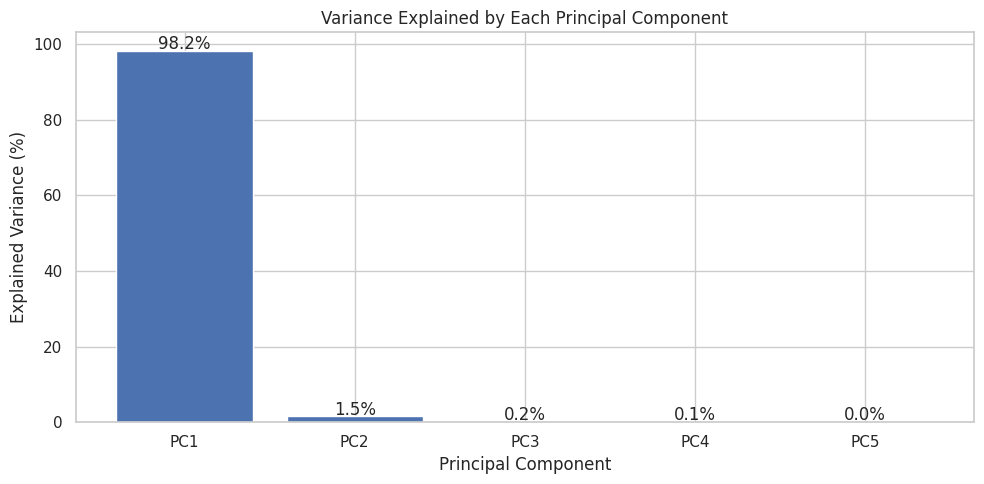

In [ ]:
# ============================================
# CELL 12: EXPLAINED VARIANCE CHART
# ============================================

plt.figure(figsize=(10, 5))

pc_labels = [f"PC{i}" for i in range(1, 6)]

bars = plt.bar(
    pc_labels,
    explained_variance_ratio * 100
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Variance Explained by Each Principal Component")

# Add values above bars
for bar, value in zip(bars, explained_variance_ratio * 100):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

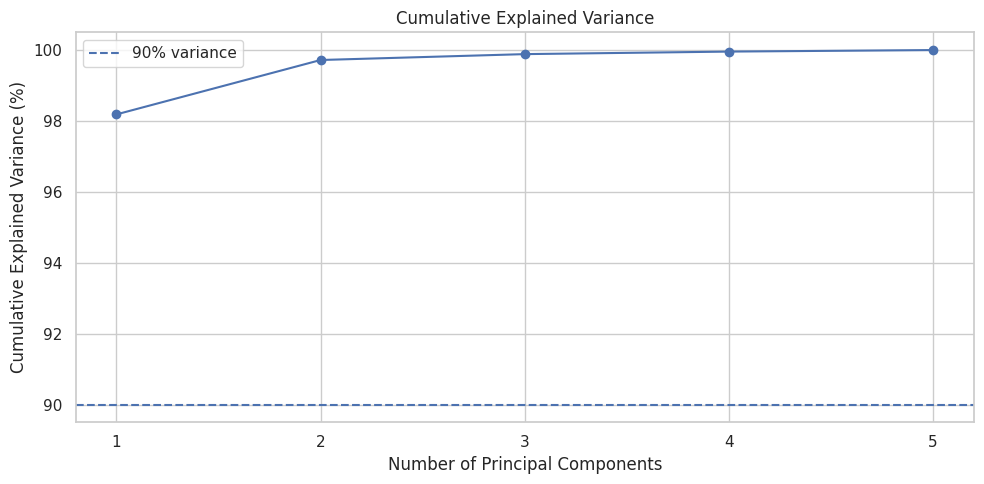

In [ ]:
# ============================================
# CELL 13: CUMULATIVE EXPLAINED VARIANCE
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 6),
    cumulative_variance * 100,
    marker="o"
)

plt.xticks(range(1, 6))
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")

# 90% reference line
plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance"
)

plt.legend()
plt.tight_layout()
plt.show()

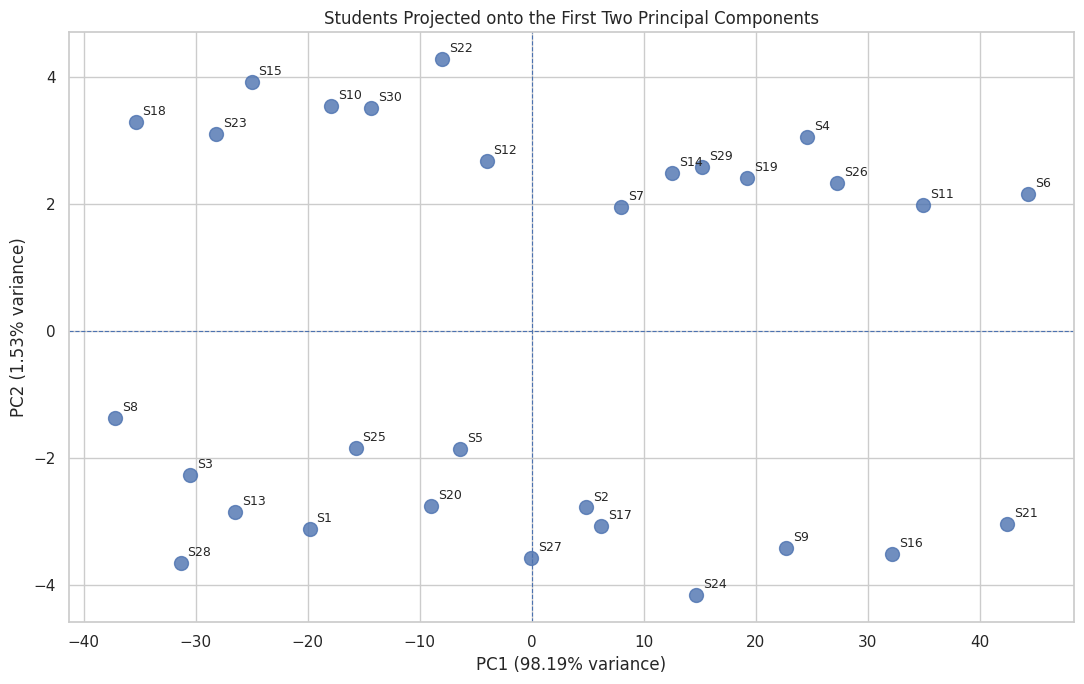

In [ ]:
# ============================================
# CELL 14: PCA 2D SCATTER PLOT
# ============================================

plt.figure(figsize=(11, 7))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    s=100,
    alpha=0.8
)

# Label every student
for student, x, y in zip(
    student_names,
    pca_df["PC1"],
    pca_df["PC2"]
):
    plt.annotate(
        student.replace("Student ", "S"),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.axhline(0, linestyle="--", linewidth=0.8)
plt.axvline(0, linestyle="--", linewidth=0.8)

plt.xlabel(
    f"PC1 ({explained_variance_ratio[0] * 100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({explained_variance_ratio[1] * 100:.2f}% variance)"
)

plt.title("Students Projected onto the First Two Principal Components")

plt.tight_layout()
plt.show()

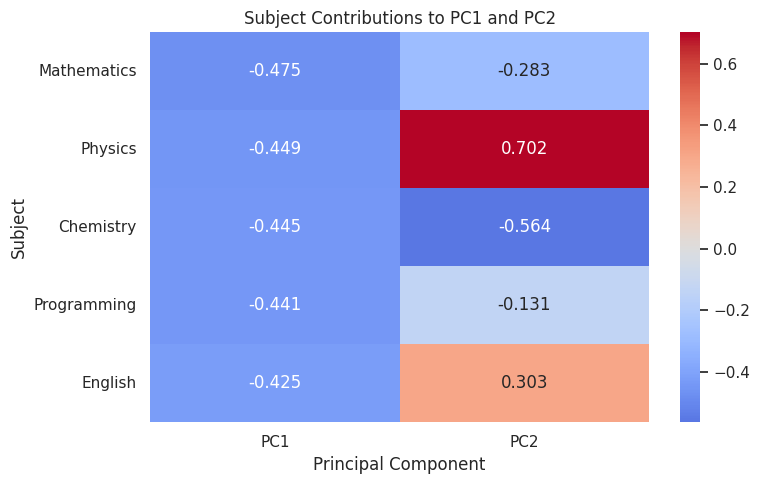

In [ ]:
# ============================================
# CELL 15: PCA LOADING HEATMAP
# ============================================

plt.figure(figsize=(8, 5))

sns.heatmap(
    pc_table,
    annot=True,
    fmt=".3f",
    center=0,
    cmap="coolwarm"
)

plt.title("Subject Contributions to PC1 and PC2")
plt.xlabel("Principal Component")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()

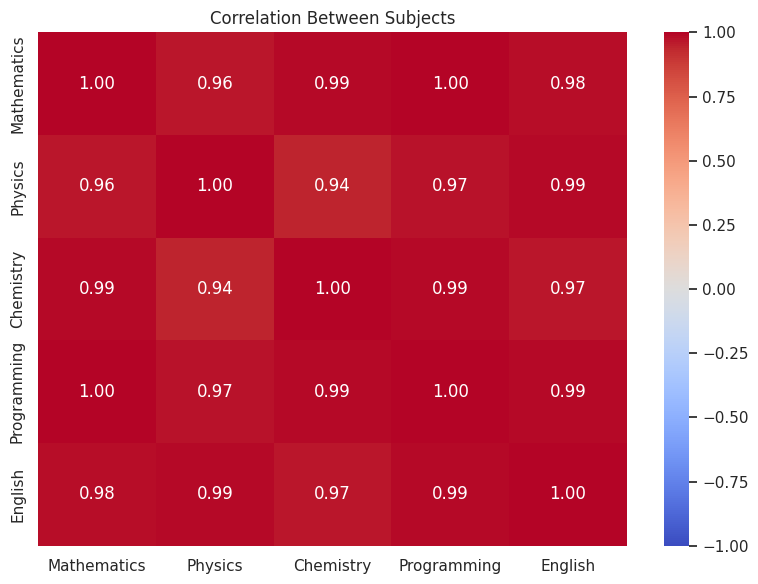

In [ ]:
# ============================================
# CELL 16: SUBJECT CORRELATION HEATMAP
# ============================================

correlation_matrix = np.corrcoef(
    marks,
    rowvar=False
)

correlation_df = pd.DataFrame(
    correlation_matrix,
    index=subjects,
    columns=subjects
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Subjects")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CELL 17: FINAL PROJECT REPORT
# ============================================

print("=" * 60)
print("PRINCIPAL COMPONENT ANALYSIS — FINAL RESULTS")
print("=" * 60)

print(f"\nNumber of students       : {n_students}")
print(f"Number of subjects       : {len(subjects)}")

print("\nSubject means:")
for subject, mean in zip(subjects, subject_means):
    print(f"  {subject:15s}: {mean:.2f}")

print("\nEigenvalues:")
for i, value in enumerate(eigenvalues, start=1):
    print(f"  λ{i}: {value:.4f}")

print("\nExplained variance:")
for i, percentage in enumerate(
    explained_variance_ratio * 100,
    start=1
):
    print(f"  PC{i}: {percentage:.2f}%")

print(
    f"\nVariance retained by PC1 + PC2: "
    f"{cumulative_variance[1] * 100:.2f}%"
)

print("\nTop 2 principal components:")
print("  PC1 =", np.round(W[:, 0], 4))
print("  PC2 =", np.round(W[:, 1], 4))

print("\nMost similar students based on PCA distance:")
display(most_similar.head(5).round(4))

print("\nConclusion:")
print(
    "The original 5-dimensional student-mark data has been "
    "reduced to a 2-dimensional representation using PCA. "
    "Students that appear close together in the PCA plot "
    "have similar overall patterns of performance across "
    "the five subjects."
)

PRINCIPAL COMPONENT ANALYSIS — FINAL RESULTS

Number of students       : 30
Number of subjects       : 5

Subject means:
  Mathematics    : 76.80
  Physics        : 76.57
  Chemistry      : 76.00
  Programming    : 81.33
  English        : 76.23

Eigenvalues:
  λ1: 586.8828
  λ2: 9.1711
  λ3: 0.9914
  λ4: 0.4268
  λ5: 0.2590

Explained variance:
  PC1: 98.19%
  PC2: 1.53%
  PC3: 0.17%
  PC4: 0.07%
  PC5: 0.04%

Variance retained by PC1 + PC2: 99.72%

Top 2 principal components:
  PC1 = [-0.4749 -0.449  -0.4452 -0.4408 -0.4247]
  PC2 = [-0.2835  0.7018 -0.564  -0.1315  0.3028]

Most similar students based on PCA distance:


,Student 1,Student 2,PCA Distance
43,Student 2,Student 17,1.3834
81,Student 3,Student 28,1.6073
313,Student 14,Student 29,2.6775
124,Student 5,Student 20,2.7779
105,Student 4,Student 26,2.7804



Conclusion:
The original 5-dimensional student-mark data has been reduced to a 2-dimensional representation using PCA. Students that appear close together in the PCA plot have similar overall patterns of performance across the five subjects.


In [ ]:
# ============================================
# CELL 18: CUSTOM DATASET TEMPLATE
# ============================================

# Replace the numbers below with your own marks.
# You MUST provide exactly 30 rows and 5 columns.

custom_marks = np.array([
    # Mathematics, Physics, Chemistry, Programming, English
    [80, 75, 82, 88, 79],
    [72, 70, 74, 76, 73],
    # Add 28 more students...
])

# Uncomment the following section after entering
# all 30 students.

# assert custom_marks.shape == (30, 5)
# assert np.all((custom_marks >= 0) & (custom_marks <= 100))

# marks = custom_marks
# student_names = [f"Student {i}" for i in range(1, 31)]

# Then rerun Cells 4–17.

In [22]:
# ============================================
# CELL 1: FRONTEND IMPORTS
# ============================================

from IPython.display import display, HTML, Javascript
import pandas as pd
import numpy as np

print("Frontend libraries loaded successfully!")

Frontend libraries loaded successfully!


In [23]:
# ============================================
# CELL 2: PROJECT HEADER
# ============================================

display(HTML("""
<style>

.pca-header {
    background: linear-gradient(135deg, #172554, #2563eb);
    color: white;
    padding: 35px;
    border-radius: 20px;
    text-align: center;
    margin-bottom: 25px;
    box-shadow: 0 8px 25px rgba(0,0,0,0.15);
}

.pca-header h1 {
    font-size: 38px;
    margin: 0;
    font-weight: 700;
}

.pca-header p {
    font-size: 17px;
    margin-top: 10px;
}

.pca-badge {
    display: inline-block;
    background: rgba(255,255,255,0.18);
    padding: 8px 18px;
    border-radius: 20px;
    margin-top: 12px;
}

</style>

<div class="pca-header">

    <h1>📊 Principal Component Analysis</h1>

    <p>
        Student Performance Analysis using
        Eigenvalues, Eigenvectors and PCA
    </p>

    <div class="pca-badge">
        B.Tech Mathematics Mini Project — B5
    </div>

</div>
"""))

In [24]:
# ============================================
# CELL 3: PROJECT INFORMATION
# ============================================

display(HTML("""
<style>

.info-container {
    display: flex;
    gap: 15px;
    flex-wrap: wrap;
    margin-bottom: 25px;
}

.info-card {
    flex: 1;
    min-width: 180px;
    background: white;
    border-radius: 15px;
    padding: 20px;
    text-align: center;
    box-shadow: 0 4px 15px rgba(0,0,0,0.08);
    border: 1px solid #e5e7eb;
}

.info-card .icon {
    font-size: 30px;
}

.info-card h3 {
    margin: 8px 0;
    color: #1e3a8a;
}

.info-card p {
    margin: 0;
    color: #64748b;
}

</style>

<div class="info-container">

    <div class="info-card">
        <div class="icon">👨‍🎓</div>
        <h3>30</h3>
        <p>Students</p>
    </div>

    <div class="info-card">
        <div class="icon">📚</div>
        <h3>5</h3>
        <p>Subjects</p>
    </div>

    <div class="info-card">
        <div class="icon">🧮</div>
        <h3>PCA</h3>
        <p>Mathematical Method</p>
    </div>

    <div class="info-card">
        <div class="icon">🎯</div>
        <h3>2D</h3>
        <p>Final Projection</p>
    </div>

</div>
"""))

In [25]:
# ============================================
# CELL 4: STUDENT DATA TABLE
# ============================================

student_table = pd.DataFrame(
    marks,
    columns=subjects
)

student_table.insert(
    0,
    "Student",
    student_names
)

display(HTML("""
<h2 style="
    color:#1e3a8a;
    margin-top:25px;
">
📝 Student Marks Dataset
</h2>

<p style="color:#64748b;">
Marks of 30 students across 5 subjects.
</p>
"""))

display(
    student_table.style
    .format({
        subject: "{:.0f}"
        for subject in subjects
    })
    .set_properties(**{
        "text-align": "center"
    })
)

,Student,Mathematics,Physics,Chemistry,Programming,English
0,Student 1,88,84,86,91,82
1,Student 2,76,72,75,79,74
2,Student 3,92,89,91,95,88
3,Student 4,65,68,63,70,66
4,Student 5,81,79,80,84,77
5,Student 6,54,58,56,61,59
6,Student 7,73,75,71,78,72
7,Student 8,95,93,94,97,91
8,Student 9,68,64,67,72,65
9,Student 10,84,87,82,89,85


In [26]:
# ============================================
# CELL 5: PCA MATHEMATICAL PROCESS
# ============================================

display(HTML("""
<style>

.math-box {
    background: #f8fafc;
    border-left: 5px solid #2563eb;
    padding: 22px;
    border-radius: 12px;
    margin: 20px 0;
}

.step {
    margin: 12px 0;
    padding: 12px;
    background: white;
    border-radius: 8px;
}

.step strong {
    color: #1e3a8a;
}

.formula {
    font-size: 20px;
    text-align: center;
    padding: 12px;
    color: #111827;
}

</style>

<h2 style="color:#1e3a8a;">
🧮 PCA Mathematical Process
</h2>

<div class="math-box">

<div class="step">
<strong>Step 1 — Center the data</strong>

<div class="formula">
X<sub>c</sub> = X − X̄
</div>

</div>

<div class="step">
<strong>Step 2 — Calculate covariance matrix</strong>

<div class="formula">
C = (1 / (n − 1)) X<sub>c</sub><sup>T</sup>X<sub>c</sub>
</div>

</div>

<div class="step">
<strong>Step 3 — Find eigenvalues and eigenvectors</strong>

<div class="formula">
Cv = λv
</div>

</div>

<div class="step">
<strong>Step 4 — Select the two largest eigenvalues</strong>

<p>
Their corresponding eigenvectors become PC1 and PC2.
</p>

</div>

<div class="step">
<strong>Step 5 — Project the students into 2D</strong>

<div class="formula">
Z = X<sub>c</sub>W
</div>

</div>

</div>
"""))

In [27]:
# ============================================
# CELL 6: SUBJECT MEANS
# ============================================

mean_table = pd.DataFrame({
    "Subject": subjects,
    "Mean Mark": subject_means
})

display(HTML("""
<h2 style="color:#1e3a8a;">
📐 Step 1 — Subject Means
</h2>
"""))

display(
    mean_table.style
    .format({"Mean Mark": "{:.2f}"})
    .set_properties(**{
        "text-align": "center"
    })
)

,Subject,Mean Mark
0,Mathematics,76.80
1,Physics,76.57
2,Chemistry,76.00
3,Programming,81.33
4,English,76.23


In [28]:
# ============================================
# CELL 7: CENTERED DATA
# ============================================

centered_df = pd.DataFrame(
    centered_data,
    columns=subjects
)

centered_df.insert(
    0,
    "Student",
    student_names
)

display(HTML("""
<h2 style="color:#1e3a8a;">
📊 Step 2 — Centered Data Matrix
</h2>

<p>
Each subject mean has been subtracted from the
corresponding marks.
</p>
"""))

display(
    centered_df.round(3)
)

,Student,Mathematics,Physics,Chemistry,Programming,English
0,Student 1,11.2,7.433,10.0,9.667,5.767
1,Student 2,-0.8,-4.567,-1.0,-2.333,-2.233
2,Student 3,15.2,12.433,15.0,13.667,11.767
3,Student 4,-11.8,-8.567,-13.0,-11.333,-10.233
4,Student 5,4.2,2.433,4.0,2.667,0.767
5,Student 6,-22.8,-18.567,-20.0,-20.333,-17.233
6,Student 7,-3.8,-1.567,-5.0,-3.333,-4.233
7,Student 8,18.2,16.433,18.0,15.667,14.767
8,Student 9,-8.8,-12.567,-9.0,-9.333,-11.233
9,Student 10,7.2,10.433,6.0,7.667,8.767


In [29]:
# ============================================
# CELL 8: COVARIANCE MATRIX
# ============================================

covariance_display = pd.DataFrame(
    covariance_matrix,
    index=subjects,
    columns=subjects
)

display(HTML("""
<h2 style="color:#1e3a8a;">
🔢 Step 3 — Covariance Matrix
</h2>

<div style="
background:#eff6ff;
padding:15px;
border-radius:10px;
margin-bottom:15px;
">

<strong>Formula:</strong>

C = (1 / (n − 1)) X<sub>c</sub><sup>T</sup>X<sub>c</sub>

</div>
"""))

display(
    covariance_display.round(4)
)

,Mathematics,Physics,Chemistry,Programming,English
Mathematics,133.4759,123.3931,125.3103,123.2069,117.2897
Physics,123.3931,123.0126,113.7241,115.2874,113.5529
Chemistry,125.3103,113.7241,119.5172,115.7241,109.5172
Programming,123.2069,115.2874,115.7241,114.4368,109.4023
English,117.2897,113.5529,109.5172,109.4023,107.2885


In [30]:
# ============================================
# CELL 9: EIGENVALUES
# ============================================

eigenvalue_display = pd.DataFrame({
    "Component": [
        f"PC{i}"
        for i in range(1, 6)
    ],

    "Eigenvalue":
        eigenvalues,

    "Explained Variance (%)":
        explained_variance_ratio * 100,

    "Cumulative Variance (%)":
        cumulative_variance * 100
})

display(HTML("""
<h2 style="color:#1e3a8a;">
🧮 Step 4 — Eigenvalues
</h2>
"""))

display(
    eigenvalue_display.round(4)
)

,Component,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,PC1,586.8828,98.1851,98.1851
1,PC2,9.1711,1.5343,99.7194
2,PC3,0.9914,0.1659,99.8853
3,PC4,0.4268,0.0714,99.9567
4,PC5,0.2590,0.0433,100.0000


In [31]:
# ============================================
# CELL 10: EIGENVECTORS
# ============================================

eigenvector_display = pd.DataFrame(
    eigenvectors,
    index=subjects,
    columns=[
        f"PC{i}"
        for i in range(1, 6)
    ]
)

display(HTML("""
<h2 style="color:#1e3a8a;">
🧭 Step 5 — Eigenvectors
</h2>

<p>
The eigenvectors corresponding to the two largest
eigenvalues form the first two principal components.
</p>
"""))

display(
    eigenvector_display.round(5)
)

,PC1,PC2,PC3,PC4,PC5
Mathematics,-0.47488,-0.28346,0.50645,0.35449,0.55856
Physics,-0.44899,0.70180,0.30813,-0.45908,-0.01362
Chemistry,-0.44524,-0.56405,-0.29917,-0.62776,0.00488
Programming,-0.44081,-0.13147,0.14868,0.35368,-0.80075
English,-0.42467,0.30281,-0.73277,0.38001,0.21585


In [32]:
# ============================================
# CELL 11: TOP 2 PRINCIPAL COMPONENTS
# ============================================

top_pc_table = pd.DataFrame(
    W,
    index=subjects,
    columns=["PC1", "PC2"]
)

display(HTML("""
<h2 style="color:#1e3a8a;">
⭐ Top 2 Principal Components
</h2>

<div style="
background:#f0fdf4;
padding:18px;
border-radius:12px;
border-left:5px solid #16a34a;
">

The two eigenvectors associated with the largest
eigenvalues are selected as the principal components.

</div>
"""))

display(
    top_pc_table.round(5)
)

,PC1,PC2
Mathematics,-0.47488,-0.28346
Physics,-0.44899,0.70180
Chemistry,-0.44524,-0.56405
Programming,-0.44081,-0.13147
English,-0.42467,0.30281


In [33]:
# ============================================
# CELL 12: PCA COORDINATES
# ============================================

pca_display = pd.DataFrame(
    pca_coordinates,
    columns=["PC1", "PC2"]
)

pca_display.insert(
    0,
    "Student",
    student_names
)

display(HTML("""
<h2 style="color:#1e3a8a;">
🎯 Step 6 — Students Projected into 2D
</h2>

<div style="
background:#eff6ff;
padding:15px;
border-radius:10px;
margin-bottom:15px;
">

<strong>Projection formula:</strong>

Z = X<sub>c</sub>W

</div>
"""))

display(
    pca_display.round(4)
)

,Student,PC1,PC2
0,Student 1,-19.8186,-3.1231
1,Student 2,4.8525,-2.7836
2,Student 3,-30.5006,-2.2772
3,Student 4,24.5797,3.0565
4,Student 5,-6.3691,-1.8574
5,Student 6,44.3499,2.1684
6,Student 7,8.0013,1.9542
7,Student 8,-37.2125,-1.3670
8,Student 9,22.7131,-3.4230
9,Student 10,-17.8775,3.5437


In [34]:
# ============================================
# CELL 13: PCA SUMMARY
# ============================================

pc1_percentage = explained_variance_ratio[0] * 100
pc2_percentage = explained_variance_ratio[1] * 100
total_2d_percentage = cumulative_variance[1] * 100

display(HTML(f"""
<style>

.result-container {{
    display:flex;
    gap:15px;
    flex-wrap:wrap;
}}

.result-card {{
    flex:1;
    min-width:220px;
    padding:25px;
    border-radius:16px;
    background:white;
    box-shadow:0 5px 18px rgba(0,0,0,0.08);
    text-align:center;
}}

.result-card h2 {{
    color:#2563eb;
    margin:5px;
}}

.result-card p {{
    color:#64748b;
}}

</style>

<h2 style="color:#1e3a8a;">
📌 PCA Results Summary
</h2>

<div class="result-container">

<div class="result-card">
<h2>{eigenvalues[0]:.2f}</h2>
<p>Largest Eigenvalue</p>
</div>

<div class="result-card">
<h2>{pc1_percentage:.2f}%</h2>
<p>PC1 Variance</p>
</div>

<div class="result-card">
<h2>{pc2_percentage:.2f}%</h2>
<p>PC2 Variance</p>
</div>

<div class="result-card">
<h2>{total_2d_percentage:.2f}%</h2>
<p>Variance Retained in 2D</p>
</div>

</div>
"""))

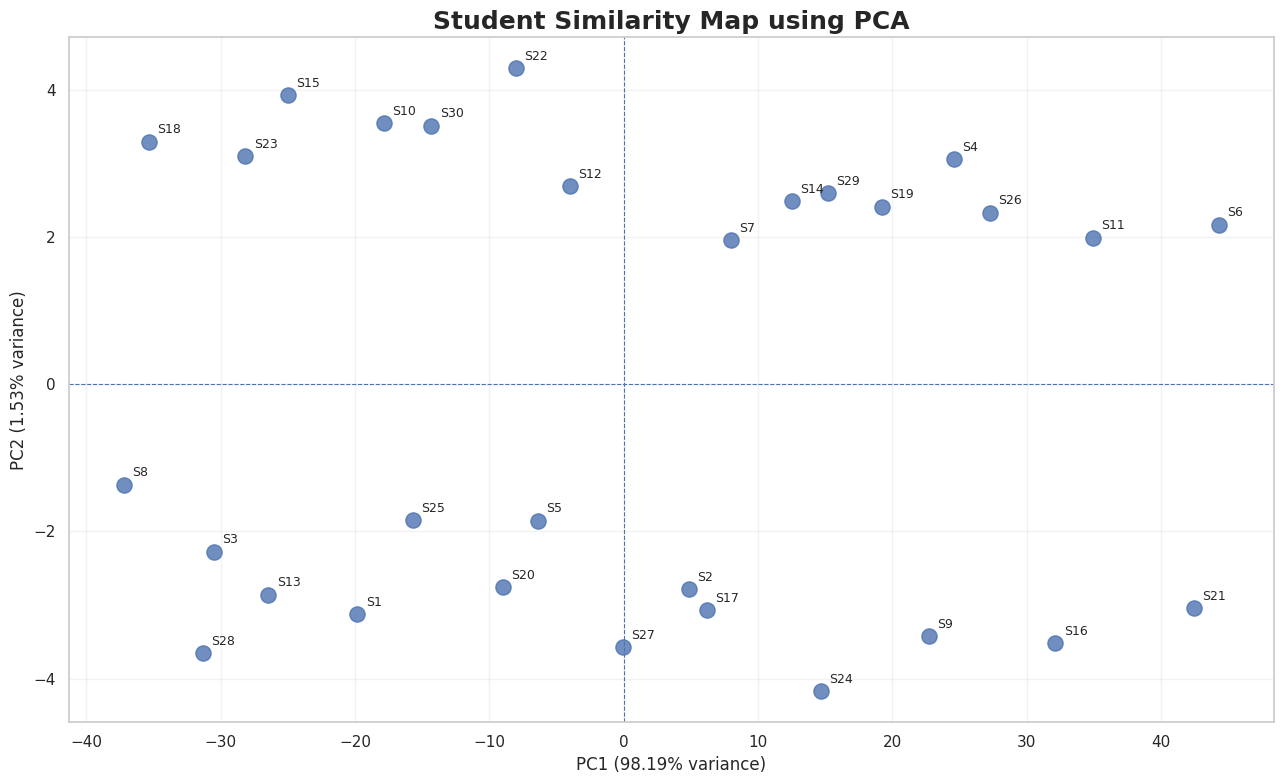

In [35]:
# ============================================
# CELL 14: 2D PCA STUDENT MAP
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 8))

plt.scatter(
    pca_coordinates[:, 0],
    pca_coordinates[:, 1],
    s=120,
    alpha=0.8
)

for i in range(len(student_names)):

    plt.annotate(
        f"S{i+1}",
        (
            pca_coordinates[i, 0],
            pca_coordinates[i, 1]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

plt.axhline(
    0,
    linestyle="--",
    linewidth=0.8
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=0.8
)

plt.xlabel(
    f"PC1 ({pc1_percentage:.2f}% variance)",
    fontsize=12
)

plt.ylabel(
    f"PC2 ({pc2_percentage:.2f}% variance)",
    fontsize=12
)

plt.title(
    "Student Similarity Map using PCA",
    fontsize=18,
    fontweight="bold"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()

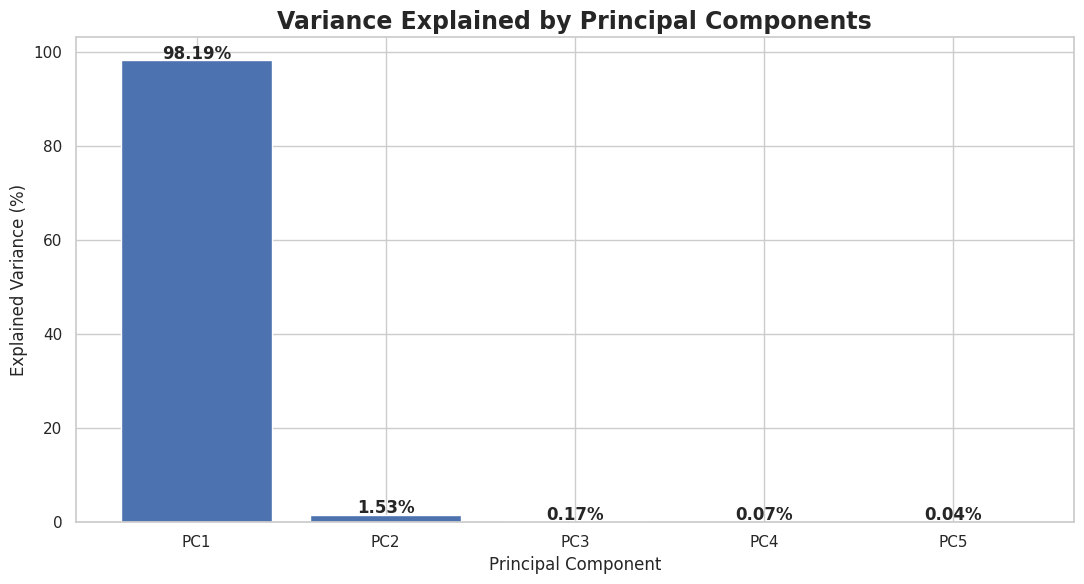

In [36]:
# ============================================
# CELL 15: EXPLAINED VARIANCE CHART
# ============================================

plt.figure(figsize=(11, 6))

components = [
    f"PC{i}"
    for i in range(1, 6)
]

values = (
    explained_variance_ratio * 100
)

bars = plt.bar(
    components,
    values
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Variance Explained by Principal Components",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel(
    "Principal Component"
)

plt.ylabel(
    "Explained Variance (%)"
)

plt.tight_layout()

plt.show()

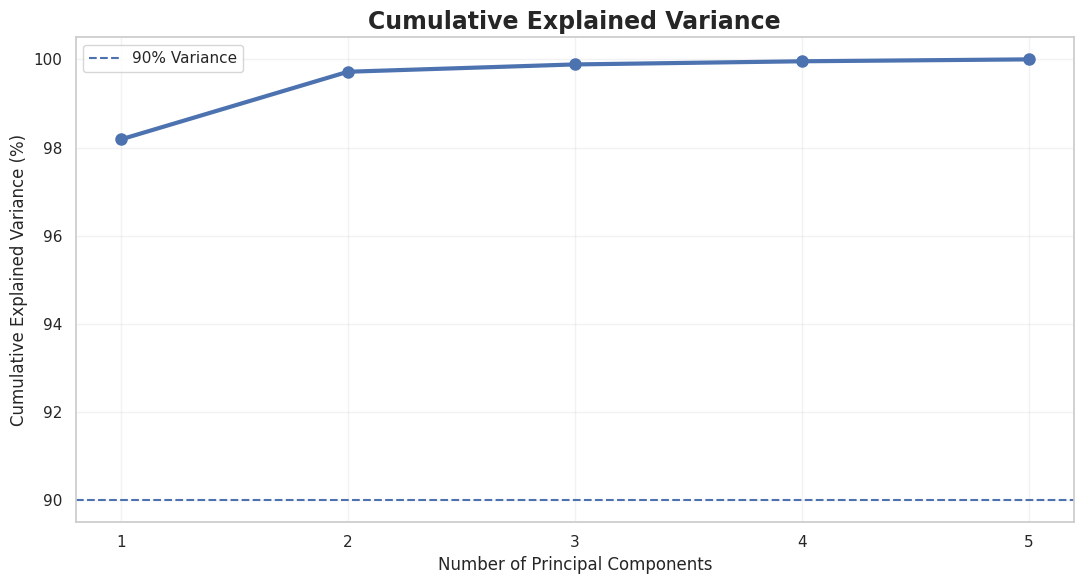

In [37]:
# ============================================
# CELL 16: CUMULATIVE VARIANCE
# ============================================

plt.figure(figsize=(11, 6))

plt.plot(
    range(1, 6),
    cumulative_variance * 100,
    marker="o",
    linewidth=3,
    markersize=8
)

plt.axhline(
    90,
    linestyle="--",
    label="90% Variance"
)

plt.xticks(
    range(1, 6)
)

plt.xlabel(
    "Number of Principal Components"
)

plt.ylabel(
    "Cumulative Explained Variance (%)"
)

plt.title(
    "Cumulative Explained Variance",
    fontsize=17,
    fontweight="bold"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()

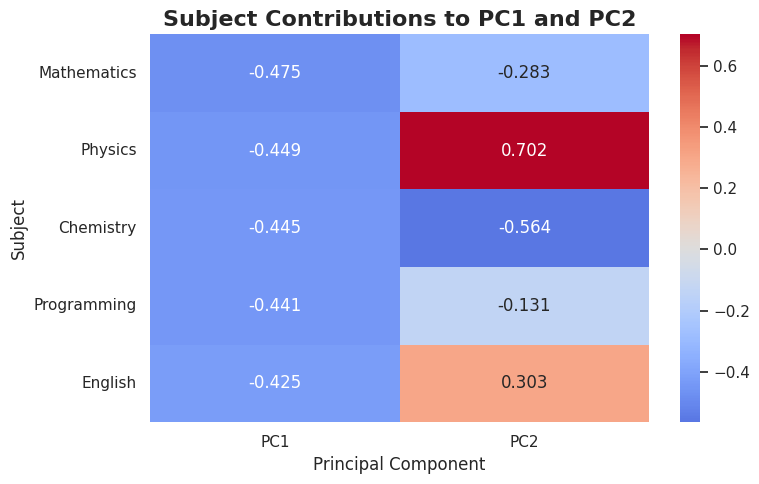

In [38]:
# ============================================
# CELL 17: PCA LOADING HEATMAP
# ============================================

import seaborn as sns

plt.figure(figsize=(8, 5))

sns.heatmap(
    top_pc_table,
    annot=True,
    fmt=".3f",
    center=0,
    cmap="coolwarm"
)

plt.title(
    "Subject Contributions to PC1 and PC2",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Principal Component"
)

plt.ylabel(
    "Subject"
)

plt.tight_layout()

plt.show()

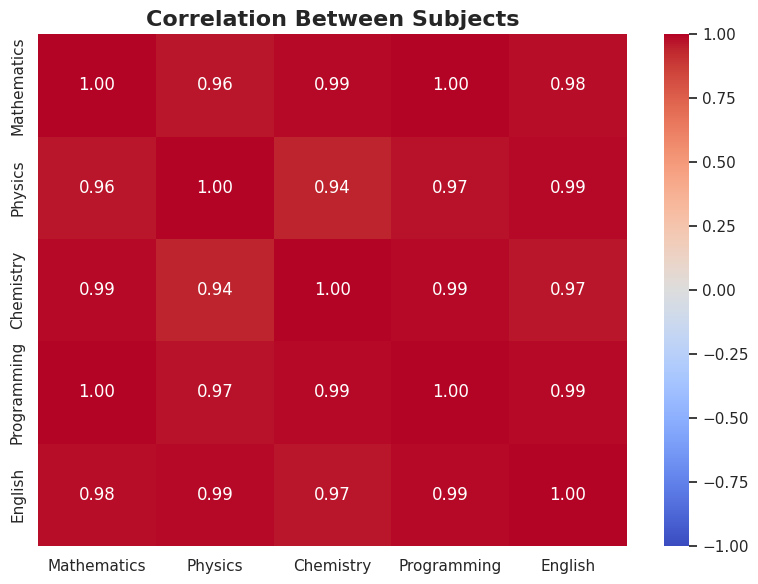

In [39]:
# ============================================
# CELL 18: SUBJECT CORRELATION
# ============================================

correlation_matrix = np.corrcoef(
    marks,
    rowvar=False
)

correlation_df = pd.DataFrame(
    correlation_matrix,
    index=subjects,
    columns=subjects
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Between Subjects",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

In [40]:
# ============================================
# CELL 19: SIMILAR STUDENTS
# ============================================

from itertools import combinations

student_pairs = []

for i, j in combinations(
    range(len(student_names)),
    2
):

    distance = np.linalg.norm(
        pca_coordinates[i]
        - pca_coordinates[j]
    )

    student_pairs.append({
        "Student 1": student_names[i],
        "Student 2": student_names[j],
        "PCA Distance": distance
    })

similarity_df = pd.DataFrame(
    student_pairs
)

similarity_df = similarity_df.sort_values(
    "PCA Distance"
)

display(HTML("""
<h2 style="color:#1e3a8a;">
👥 Most Similar Students
</h2>

<p>
Students with smaller PCA distances have more similar
overall performance patterns in the reduced 2D space.
</p>
"""))

display(
    similarity_df
    .head(10)
    .round(4)
)

,Student 1,Student 2,PCA Distance
43,Student 2,Student 17,1.3834
81,Student 3,Student 28,1.6073
313,Student 14,Student 29,2.6775
124,Student 5,Student 20,2.7779
105,Student 4,Student 26,2.7804
322,Student 15,Student 23,3.2600
244,Student 10,Student 30,3.5698
378,Student 19,Student 29,4.0325
66,Student 3,Student 13,4.0942
23,Student 1,Student 25,4.3032


In [41]:
# ============================================
# CELL 20: FINAL PROJECT CONCLUSION
# ============================================

display(HTML(f"""
<style>

.final-box {{
    background: linear-gradient(
        135deg,
        #eff6ff,
        #f8fafc
    );

    padding: 30px;

    border-radius: 18px;

    border-left: 6px solid #2563eb;

    margin-top: 25px;
}}

.final-box h2 {{
    color: #1e3a8a;
}}

.final-box strong {{
    color: #2563eb;
}}

</style>

<div class="final-box">

<h2>🎓 Final Mathematical Result</h2>

<p>
The original student dataset contains
<strong>5 dimensions</strong>, representing the five subjects:
Mathematics, Physics, Chemistry, Programming and English.
</p>

<p>
After centering the data, the covariance matrix was calculated
and its eigenvalues and eigenvectors were obtained.
</p>

<p>
The eigenvectors corresponding to the two largest eigenvalues
were selected as <strong>PC1</strong> and <strong>PC2</strong>.
</p>

<p>
<strong>PC1 explains {pc1_percentage:.2f}%</strong>
of the total variance, while
<strong>PC2 explains {pc2_percentage:.2f}%</strong>.
</p>

<p>
Together, the first two principal components preserve
<strong>{total_2d_percentage:.2f}%</strong>
of the total variation in the student dataset.
</p>

<p>
The 30 students can therefore be represented in a
<strong>2-dimensional PCA space</strong>, where students
located close to each other have similar patterns of
academic performance.
</p>

</div>
"""))

In [42]:
# ============================================
# CELL 21: DOWNLOAD RESULTS
# ============================================

from google.colab import files

# Create final result table

final_results = pd.DataFrame({
    "Student": student_names,
    "PC1": pca_coordinates[:, 0],
    "PC2": pca_coordinates[:, 1]
})

# Save CSV

output_file = "student_pca_results.csv"

final_results.to_csv(
    output_file,
    index=False
)

display(HTML("""
<h2 style="color:#1e3a8a;">
⬇️ Download Results
</h2>

<p>
The final 2D PCA coordinates are ready as a CSV file.
</p>
"""))

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>